# Lab 3: Nim با Minimax و Alpha-Beta + EDA کامل داده بازی‌ها
## توسعهٔ انتخابی: «قانون معکوس» (Misère)

**قانون عادی (normal):** کسی که آخرین سنگ را بردارد **برنده** است.
**قانون معکوس (misère):** کسی که آخرین سنگ را بردارد **بازنده** است.

**تغییرات نسبت به کد کلاسی (همه عملی در کد):**
1. تابع جدید `terminal_value(player, misere)`؛ ارزش حالت پایانی را بر اساس قانون برمی‌گرداند.
2. به `minimax`، `alphabeta` و `best_move` پارامتر `misere=False` اضافه شد (رفتار پیش‌فرض همان قانون عادی است).
3. سلول اعتبارسنجی: Minimax با Alpha-Beta و با فرمول نظریهٔ Misère روی همهٔ حالت‌ها مقایسه می‌شود.
4. جدول داده: برای هر شروع، نتیجهٔ هر دو قانون ثبت می‌شود تا بتوان آن‌ها را مقایسه کرد؛ بازی‌ها با قانون معکوس انجام می‌شوند.
5. EDA کامل (گام ۳) روی همین جدول، با تفسیر «مشاهده، دلیل، نتیجه» در انتها.

## Cell 1: The game (با قانون معکوس)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

START = (3, 4, 5)            # stones in each pile
nodes = 0                    # how many positions the search looks at

def moves(piles, order="small_first"):
    """All positions we can reach by taking some stones from ONE pile."""
    result = []
    for i, n in enumerate(piles):
        takes = range(1, n + 1) if order == "small_first" else range(n, 0, -1)
        for take in takes:
            new = list(piles)
            new[i] = n - take
            result.append(tuple(new))
    return result

def terminal_value(player, misere=False):
    """Value of an empty board. `player` is the one who must move now,
    so the OTHER player took the last stone.
    normal : the taker wins.   misere : the taker loses."""
    taker_is_A = (player == "B")
    a_wins = taker_is_A if not misere else (not taker_is_A)
    return 1 if a_wins else -1

print(moves((1, 2)))
print("empty board, A to move | normal:", terminal_value("A"), "| misere:", terminal_value("A", True))

[(0, 2), (1, 1), (1, 0)]
empty board, A to move | normal: -1 | misere: 1


## Cell 2: Minimax

In [2]:
def minimax(piles, player, misere=False):
    """+1 if player A wins, -1 if player B wins (both play perfectly)."""
    global nodes
    nodes += 1
    if sum(piles) == 0:
        return terminal_value(player, misere)
    values = [minimax(nxt, "B" if player == "A" else "A", misere) for nxt in moves(piles)]
    return max(values) if player == "A" else min(values)

## Cell 3: Alpha-beta pruning

In [3]:
def alphabeta(piles, player, alpha, beta, order, misere=False):
    global nodes
    nodes += 1
    if sum(piles) == 0:
        return terminal_value(player, misere)
    if player == "A":
        value = -2
        for nxt in moves(piles, order):
            value = max(value, alphabeta(nxt, "B", alpha, beta, order, misere))
            alpha = max(alpha, value)
            if alpha >= beta:
                break                      # prune: B will never allow this branch
        return value
    value = 2
    for nxt in moves(piles, order):
        value = min(value, alphabeta(nxt, "A", alpha, beta, order, misere))
        beta = min(beta, value)
        if alpha >= beta:
            break                          # prune: A already has a better option
    return value

## Cell 4: Count the nodes (هر دو قانون)

In [4]:
def count(rule_misere):
    global nodes
    nodes = 0; v1 = minimax(START, "A", rule_misere); n1 = nodes
    nodes = 0; v2 = alphabeta(START, "A", -2, 2, "small_first", rule_misere); n2 = nodes
    nodes = 0; v3 = alphabeta(START, "A", -2, 2, "big_first", rule_misere); n3 = nodes
    return (v1, v2, v3), n1, n2, n3

for name, flag in [("normal", False), ("misere", True)]:
    vals, n1, n2, n3 = count(flag)
    print(f"--- {name} ---")
    print("value of START (+1 = A wins):", vals)
    print("minimax nodes:           ", n1)
    print("alpha-beta (natural):    ", n2)
    print("alpha-beta (big first):  ", n3)

--- normal ---
value of START (+1 = A wins): (1, 1, 1)
minimax nodes:            1038768
alpha-beta (natural):     33916
alpha-beta (big first):   4332
--- misere ---
value of START (+1 = A wins): (1, 1, 1)
minimax nodes:            1038768
alpha-beta (natural):     30492
alpha-beta (big first):   3763


## Cell 4b: اعتبارسنجی قانون معکوس
دو آزمون:
1. روی همهٔ حالت‌های `0..3` سه‌پشته‌ای: جواب Minimax و Alpha-Beta یکی باشد (برای هر دو قانون).
2. روی همهٔ حالت‌های `0..4`: جواب جستجو با فرمول نظریهٔ Misère یکی باشد:
   - اگر حداقل یک پشته ≥ ۲ باشد: بازیکن نوبت‌دار می‌برد ⇔ `nim_sum != 0` (مثل قانون عادی)
   - اگر همه پشته‌ها ≤ ۱ باشند (k پشتهٔ تک‌سنگی): بازیکن نوبت‌دار می‌برد ⇔ `k` زوج باشد

In [5]:
from itertools import product

def misere_theory(piles):
    """First player wins under the misere rule? (Bouton's theorem for misere Nim)"""
    if max(piles) >= 2:
        return (piles[0] ^ piles[1] ^ piles[2]) != 0
    return sum(piles) % 2 == 0

# test 1: minimax == alphabeta
bad1 = 0
for p in product(range(4), repeat=3):
    if sum(p) == 0: continue
    for flag in (False, True):
        if minimax(p, "A", flag) != alphabeta(p, "A", -2, 2, "big_first", flag):
            bad1 += 1
print("minimax vs alphabeta mismatches:", bad1)

# test 2: search == theory
bad2 = 0
for p in product(range(5), repeat=3):
    if sum(p) == 0: continue
    search = alphabeta(p, "A", -2, 2, "big_first", True) > 0
    if search != misere_theory(p):
        bad2 += 1
print("search vs misere theory mismatches:", bad2)

minimax vs alphabeta mismatches: 0
search vs misere theory mismatches: 0


## Cell 5: Build the data table (200 games) and save it as CSV

In [6]:
def best_move(piles, player, misere=False):
    best_nxt, best_value = None, None
    for nxt in moves(piles, "big_first"):
        value = alphabeta(nxt, "B" if player == "A" else "A", -2, 2, "big_first", misere)
        better = best_value is None or (value > best_value if player == "A" else value < best_value)
        if better:
            best_nxt, best_value = nxt, value
    return best_nxt

MISERE = True                      # the games in the table are played with the misere rule
rng = np.random.default_rng(0)
rows = []
for game in range(200):
    piles = tuple(int(x) for x in rng.integers(1, 5, size=3))     # random start: 3 piles of 1..4 stones
    nodes = 0
    v_normal = alphabeta(piles, "A", -2, 2, "big_first", False)   # same start, normal rule
    nodes = 0
    v_misere = alphabeta(piles, "A", -2, 2, "big_first", True)    # same start, misere rule
    nodes_ab = nodes
    nodes = 0
    minimax(piles, "A", True)
    nodes_mm = nodes
    board, player, n_moves = piles, "A", 0            # play: A is smart, B plays at random
    while sum(board) > 0:
        if player == "A":
            board = best_move(board, "A", MISERE)
        else:
            options = moves(board)
            board = options[rng.integers(len(options))]
        player = "B" if player == "A" else "A"
        n_moves += 1
    # misere: the player who took the last stone LOSES, so the winner is the one now to move
    rows.append({"p1": piles[0], "p2": piles[1], "p3": piles[2], "total": sum(piles),
                 "max_pile": max(piles), "nim_sum": piles[0] ^ piles[1] ^ piles[2],
                 "first_wins_normal": v_normal > 0, "first_wins_misere": v_misere > 0,
                 "nodes_minimax": nodes_mm, "nodes_alphabeta": nodes_ab, "moves": n_moves,
                 "winner": player})

df = pd.DataFrame(rows)
df["rule_differs"] = df["first_wins_normal"] != df["first_wins_misere"]
df.to_csv("nim_games_misere.csv", index=False)        # keep the data in a file (Step 2)
print(df.head())

   p1  p2  p3  total  max_pile  nim_sum  first_wins_normal  first_wins_misere  \
0   4   3   3     10         4        4               True               True   
1   2   1   1      4         2        2               True               True   
2   1   4   3      8         4        6               True               True   
3   3   3   4     10         4        4               True               True   
4   3   3   3      9         3        3               True               True   

   nodes_minimax  nodes_alphabeta  moves winner  rule_differs  
0          83510              259      4      A         False  
1             46               24      4      A         False  
2           4348              398      4      A         False  
3          83510             5586      4      A         False  
4          24136              231      4      A         False  


## Cell 6: Data quality and descriptive statistics (EDA)

In [7]:
print("shape (rows, columns):", df.shape)
print("missing values:", df.isna().sum().sum())
print("duplicated rows:", df.duplicated().sum(), "| distinct start positions:", df[["p1", "p2", "p3"]].drop_duplicates().shape[0], "of 64 possible")
print()
print(df.dtypes)
print()
print("logical range check: piles in 1..4 ->", bool(df[["p1", "p2", "p3"]].stack().between(1, 4).all()),
      "| total == p1+p2+p3 ->", bool((df["total"] == df[["p1", "p2", "p3"]].sum(axis=1)).all()))
print()
print(df[["total", "max_pile", "nim_sum", "nodes_minimax", "nodes_alphabeta", "moves"]].describe().round(1))
print()
x = df["nodes_minimax"]
print("nodes_minimax: mean", round(x.mean(), 1), "| median", x.median(), "| variance", round(x.var(), 1),
      "| std", round(x.std(), 1), "| skew", round(x.skew(), 2))
q1, q3 = x.quantile([.25, .75])
iqr = q3 - q1
outliers = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()
print("IQR outliers in nodes_minimax:", outliers)
print()
print("winner counts:"); print(df["winner"].value_counts())
print("moves counts:"); print(df["moves"].value_counts().sort_index())

shape (rows, columns): (200, 13)
missing values: 0
duplicated rows: 114 | distinct start positions: 60 of 64 possible

p1                    int64
p2                    int64
p3                    int64
total                 int64
max_pile              int64
nim_sum               int64
first_wins_normal      bool
first_wins_misere      bool
nodes_minimax         int64
nodes_alphabeta       int64
moves                 int64
winner               object
rule_differs           bool
dtype: object

logical range check: piles in 1..4 -> True | total == p1+p2+p3 -> True

       total  max_pile  nim_sum  nodes_minimax  nodes_alphabeta  moves
count  200.0     200.0    200.0          200.0            200.0  200.0
mean     7.5       3.4      3.2        28875.3            831.6    4.6
std      2.0       0.8      2.1        68173.8           1594.7    1.1
min      3.0       1.0      0.0           16.0             12.0    3.0
25%      6.0       3.0      1.0          447.0            129.0    4.0
50% 

## Cell 7: Analytic questions

In [8]:
print("1) A (first player) wins under MISERE from", round(df["first_wins_misere"].mean() * 100, 1), "% of the starts")
print("   (under the NORMAL rule:", round(df["first_wins_normal"].mean() * 100, 1), "%)")
theory = df.apply(lambda r: misere_theory((r.p1, r.p2, r.p3)), axis=1)
print("2) search == misere theory:", (theory == df["first_wins_misere"]).mean())
print("   nim_sum != 0 agrees with first_wins_misere:", round(((df["nim_sum"] != 0) == df["first_wins_misere"]).mean(), 3))
print("3) starts where the two rules disagree:", int(df["rule_differs"].sum()), "games ->",
      sorted(set(map(tuple, df.loc[df["rule_differs"], ["p1", "p2", "p3"]].values))))
print("4) alpha-beta uses", round(df["nodes_alphabeta"].sum() / df["nodes_minimax"].sum() * 100, 1), "% of the minimax nodes")
print("5) smart A wins", round((df["winner"] == "A").mean() * 100, 1), "% of the games against a random B")
lost = df[df["winner"] == "B"]
print("   games lost by A:", len(lost), "| of them A started in a lost position:", int((~lost["first_wins_misere"]).sum()))
print()
print(df[["total", "max_pile", "nodes_minimax", "nodes_alphabeta", "moves"]].corr().round(2))

1) A (first player) wins under MISERE from 88.0 % of the starts
   (under the NORMAL rule: 90.5 %)
2) search == misere theory: 1.0
   nim_sum != 0 agrees with first_wins_misere: 0.975
3) starts where the two rules disagree: 5 games -> [(np.int64(1), np.int64(1), np.int64(1))]
4) alpha-beta uses 2.9 % of the minimax nodes
5) smart A wins 94.5 % of the games against a random B
   games lost by A: 11 | of them A started in a lost position: 11

                 total  max_pile  nodes_minimax  nodes_alphabeta  moves
total             1.00      0.78           0.61             0.57   0.40
max_pile          0.78      1.00           0.29             0.34   0.39
nodes_minimax     0.61      0.29           1.00             0.66   0.26
nodes_alphabeta   0.57      0.34           0.66             1.00   0.23
moves             0.40      0.39           0.26             0.23   1.00


## Cell 8: Charts

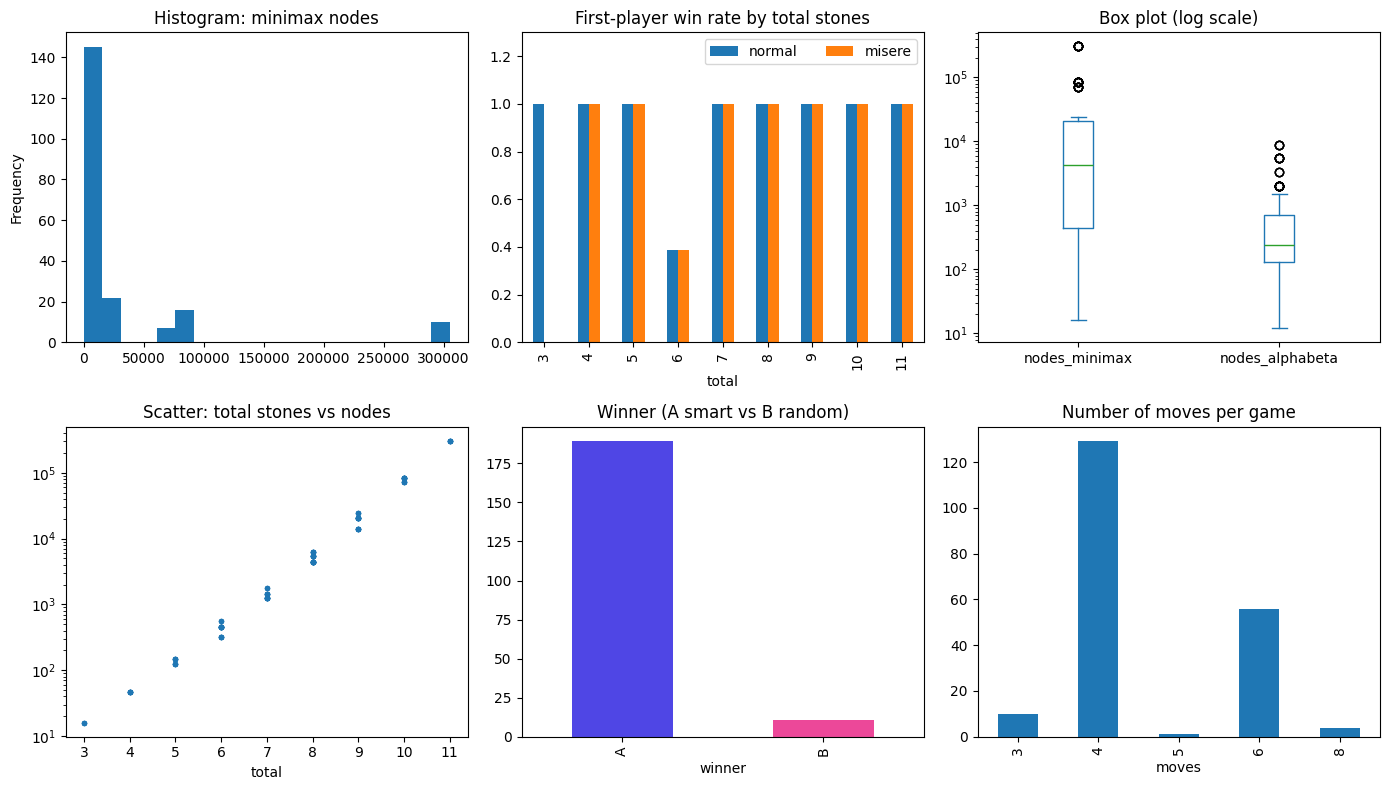

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
df["nodes_minimax"].plot(kind="hist", bins=20, ax=axes[0, 0], title="Histogram: minimax nodes")
rates = pd.DataFrame({"normal": df.groupby("total")["first_wins_normal"].mean(),
                      "misere": df.groupby("total")["first_wins_misere"].mean()})
rates.plot(kind="bar", ax=axes[0, 1], title="First-player win rate by total stones", ylim=(0, 1.3))
axes[0, 1].legend(loc="upper right", ncol=2)
df[["nodes_minimax", "nodes_alphabeta"]].plot(kind="box", logy=True, ax=axes[0, 2], title="Box plot (log scale)")
axes[1, 0].scatter(df["total"], df["nodes_minimax"], s=8)
axes[1, 0].set_yscale("log")
axes[1, 0].set_title("Scatter: total stones vs nodes"); axes[1, 0].set_xlabel("total")
df["winner"].value_counts().reindex(["A", "B"]).plot(kind="bar", ax=axes[1, 1], color=["#4f46e5", "#ec4899"],
                                                      title="Winner (A smart vs B random)")
df["moves"].value_counts().sort_index().plot(kind="bar", ax=axes[1, 2], title="Number of moves per game")
plt.tight_layout()
plt.savefig("eda_charts.png", dpi=110)
plt.show()

## Cell 9: Animation of one game (قانون معکوس)

In [10]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

rng = np.random.default_rng(1)
board, player = START, "A"
history = [(board, "start")]
while sum(board) > 0:
    old = board
    if player == "A":
        board = best_move(board, "A", True)
    else:
        options = moves(board)
        board = options[rng.integers(len(options))]
    i = [k for k in range(3) if board[k] != old[k]][0]
    history.append((board, f"{player} takes {old[i] - board[i]} from pile {i}"))
    player = "B" if player == "A" else "A"
winner = player                                  # misere: whoever took the last stone loses

fig, ax = plt.subplots(figsize=(4, 3), dpi=70)

def draw(t):
    piles, text = history[min(t, len(history) - 1)]
    ax.clear()
    ax.bar(["pile 0", "pile 1", "pile 2"], piles, color=["#4f46e5", "#ec4899", "#f59e0b"])
    ax.set_ylim(0, max(START) + 1)
    ax.set_title(text + ("   winner: " + winner + " (misere)" if t >= len(history) - 1 else ""), fontsize=9)

anim = FuncAnimation(fig, draw, frames=len(history) + 3, interval=800)
plt.close(fig)
HTML(anim.to_jshtml())